# 02 — Gate evaluation (§3.7)

This notebook checks the four saved heads against the Chapter 3 standards. It does not change the
models; it only scores them. Gate functions live in `experiment/src/ml/evaluate.py`.

| Part | Step | Data used |
| --- | --- | --- |
| A — development | 1. Load and verify | — |
| | 2. The eight metrics in five gates, with 95% CIs | `calib_conf` (7.5%) |
| | 3. Why the subgroup gap fails: breakdown with case counts | training partition, cross-validated |
| | 4. FHRS ablation and logistic-regression baselines (preview) | `calib_conf` |
| | 5. Remediation decision | results of steps 2–4 |
| B — final | 6. **Holdout, once** | `holdout` (15%) |

**Why `calib_conf` for Part A:** the models never trained on it and the calibrator never saw it
(it only set the conformal thresholds, which do not change ŷ). So it gives an honest preview without
spending the holdout.

**How "pass" is decided:** the point estimate is compared with the target. Every metric also has a
95% confidence interval from a patient-clustered bootstrap (patients are resampled, and all of a
patient's visits come along). A wide interval that crosses the target means the result is not certain.

**Run time:** about 5–10 minutes with `N_BOOT = 1000`. Set `N_BOOT = 200` for a quick look.
The holdout section does nothing until you set `RUN_HOLDOUT = True` (Step 6).

In [1]:
import sys, json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiment").is_dir())
sys.path.insert(0, str(ROOT / "experiment" / "src" / "ml"))
import data as D
import train as T
import evaluate as E

N_BOOT = 1000          # bootstrap resamples per CI (200 for a quick look)
RUN_HOLDOUT = False    # set True only once, after Step 5 is settled

FIG_DIR = ROOT / "experiment" / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
HOLDOUT_FILE = ROOT / "experiment" / "reports" / "holdout_results.json"
HEADS = D.DISEASES
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
print("Project root:", ROOT)

Project root: /home/nirmata/Desktop/thesis draft-1


## Step 1 — Load and verify

Same checks as notebook 01: the cohort hash, the saved patient split, and each bundle against the
SHA-256 in its record.

In [2]:
cohort = D.load_cohort()
df, VEL = D.add_derived(cohort)
part = D.make_partitions(df)
saved = pd.read_csv(D.PROCESSED_DIR / "partitions.csv").set_index("patient_id")["partition"]
assert (part.sort_index() == saved.sort_index()).all(), "Split differs from the saved partitions.csv"
row_part = df["patient_id"].map(part)
labels = D.patient_labels(df)

records, bundles = {}, {}
for d in HEADS:
    records[d] = json.loads((T.MODELS_DIR / f"{d}_head_latest.json").read_text())
    path = T.MODELS_DIR / f"{d}_head_latest.joblib"
    assert D.sha256_of(path) == records[d]["artifact_sha256"], f"{d}: file does not match its record"
    bundles[d] = joblib.load(path)
HASHES = {d: records[d]["artifact_sha256"] for d in HEADS}
print("Cohort, split and all four bundles verified.")
print("Patients per partition:", part.value_counts().to_dict())

Cohort, split and all four bundles verified.
Patients per partition: {'train': 10500, 'holdout': 2250, 'calib_conf': 1125, 'calib_iso': 1125}


## Step 2 — The eight metrics in five gates (`calib_conf`)

| Gate | Metric | Plain meaning |
| --- | --- | --- |
| 1 Discrimination | AUROC | chance a sick patient gets a higher score than a healthy one |
| | AUPRC | how often a high score is right; target is double the disease rate (π) |
| 2 Calibration | ECE | average gap between predicted risk and observed rate, over 10 groups |
| | Brier | squared error of the risk; must beat "give everyone the average rate", π(1−π) |
| | Calibration slope | 1 = right spread; below 1 = too extreme, above 1 = too timid |
| 3 Clinical utility | DCA net-benefit margin | how much better the model is than treating everyone or no one, at its worst threshold between 0.10 and 0.40; must not be below 0 |
| 4 Subgroup fairness | ΔAUROC | best minus worst AUROC across sex and across the three age brackets |
| 5 Stability | ICC(2,1) | agreement of risk scores when every lab value gets ±2% random noise (10 noisy copies) |

The first table is the overview; the second has every number with its CI.

In [3]:
dev_tables, DEV = [], {}
for d in HEADS:
    ev = E.eval_rows(df, labels, row_part, d, "calib_conf", bundles[d]["feature_columns"])
    tab, info = E.evaluate_gates(bundles[d], ev, VEL, n_boot=N_BOOT)
    dev_tables.append(tab.assign(head=d.upper()))
    DEV[d] = {**info, "y": ev["y"]}
    print(f"{d.upper()}: {info['n_rows']:,} rows, {info['n_patients']:,} patients, "
          f"{info['n_case_patients']} with the disease; model strictly better on DCA at "
          f"{info['dca_share_better']:.0%} of thresholds; tier changed under noise for "
          f"{info['tier_change_rate']:.1%} of rows")
dev_gates = pd.concat(dev_tables, ignore_index=True)
E.gate_summary(dev_gates)

CVD: 1,761 rows, 1,125 patients, 97 with the disease; model strictly better on DCA at 100% of thresholds; tier changed under noise for 1.8% of rows
T2D: 1,761 rows, 1,125 patients, 115 with the disease; model strictly better on DCA at 100% of thresholds; tier changed under noise for 7.2% of rows
RESP: 1,761 rows, 1,125 patients, 140 with the disease; model strictly better on DCA at 100% of thresholds; tier changed under noise for 9.7% of rows
NEURO: 1,761 rows, 1,125 patients, 79 with the disease; model strictly better on DCA at 68% of thresholds; tier changed under noise for 1.4% of rows


gate,1 Discrimination,2 Calibration,3 Clinical utility,4 Subgroup fairness,5 Stability,all gates
head,,,,,,
CVD,FAIL,pass,pass,pass,pass,FAIL
T2D,pass,pass,pass,FAIL,pass,FAIL
RESP,FAIL,FAIL,pass,FAIL,pass,FAIL
NEURO,pass,FAIL,FAIL,FAIL,pass,FAIL


In [4]:
E.fmt_gates(dev_gates)

estimate           95% CI                          target  pass
head  gate                metric                                                                                      
CVD   1 Discrimination    AUROC                           0.771    0.711 – 0.825                          ≥ 0.80  FAIL
                          AUPRC                           0.287    0.203 – 0.394                    ≥ 2π = 0.165  pass
      2 Calibration       ECE                             0.014    0.013 – 0.036                          ≤ 0.05  pass
                          Brier                          0.0676  0.0554 – 0.0814               < π(1−π) = 0.0756  pass
                          Calibration slope               0.970    0.761 – 1.196                       0.90–1.10  pass
      3 Clinical utility  DCA net-benefit margin          0.000   -0.006 – 0.006  ≥ 0 for every p_t in 0.10–0.40  pass
      4 Subgroup fairness Subgroup ΔAUROC (sex, age)      0.040    0.037 – 0.281                          < 0.05  pass
      5 Stability         ICC(2,1) under ±2% lab noise    0.996    0.994 – 0.997                          ≥ 0.85  pass
T2D   1 Discrimination    AUROC                           0.859    0.800 – 0.909                          ≥ 0.80  pass
                          AUPRC                           0.562    0.450 – 0.662                    ≥ 2π = 0.196  pass
      2 Calibration       ECE                             0.020    0.016 – 0.041                          ≤ 0.05  pass
                          Brier                          0.0585  0.0469 – 0.0709               < π(1−π) = 0.0886  pass
                          Calibration slope               0.905    0.605 – 1.220                       0.90–1.10  pass
      3 Clinical utility  DCA net-benefit margin          0.034    0.016 – 0.050  ≥ 0 for every p_t in 0.10–0.40  pass
      4 Subgroup fairness Subgroup ΔAUROC (sex, age)      0.071    0.042 – 0.211                          < 0.05  FAIL
      5 Stability         ICC(2,1) under ±2% lab noise    0.981    0.973 – 0.986                          ≥ 0.85  pass
RESP  1 Discrimination    AUROC                           0.711    0.658 – 0.760                          ≥ 0.75  FAIL
                          AUPRC                           0.298    0.235 – 0.375                    ≥ 2π = 0.251  pass
      2 Calibration       ECE                             0.026    0.021 – 0.049                          ≤ 0.05  pass
                          Brier                          0.1007  0.0864 – 0.1164               < π(1−π) = 0.1097  pass
                          Calibration slope               0.698    0.380 – 1.080                       0.90–1.10  FAIL
      3 Clinical utility  DCA net-benefit margin          0.004   -0.004 – 0.013  ≥ 0 for every p_t in 0.10–0.40  pass
      4 Subgroup fairness Subgroup ΔAUROC (sex, age)      0.071    0.037 – 0.201                          < 0.05  FAIL
      5 Stability         ICC(2,1) under ±2% lab noise    0.956    0.946 – 0.965                          ≥ 0.85  pass
NEURO 1 Discrimination    AUROC                           0.806    0.753 – 0.854                          ≥ 0.70  pass
                          AUPRC                           0.259    0.181 – 0.366                    ≥ 2π = 0.135  pass
      2 Calibration       ECE                             0.022    0.014 – 0.043                          ≤ 0.05  pass
                          Brier                          0.0588  0.0467 – 0.0719               < π(1−π) = 0.0630  pass
                          Calibration slope               0.840    0.672 – 1.040                       0.90–1.10  FAIL
      3 Clinical utility  DCA net-benefit margin         -0.004   -0.012 – 0.005  ≥ 0 for every p_t in 0.10–0.40  FAIL
      4 Subgroup fairness Subgroup ΔAUROC (sex, age)      0.064    0.029 – 0.236                          < 0.05  FAIL
      5 Stability         ICC(2,1) under ±2% lab noise    0.994    0.992 – 0.996                          ≥ 0.85  pass

**Decision curves.** The model line (blue) should stay on or above both "treat all" (orange, dashed)
and "treat none" (grey, 0) across the shaded range 0.10–0.40. Where it dips under, using the model at that
threshold would be worse than a blanket policy. At a high threshold where the model flags no one, it
touches the treat-none line: that is a tie, not a loss, so the gate requires a margin of at least 0
(never worse than either strategy). The printout above gives the share of thresholds where the model is
strictly better.

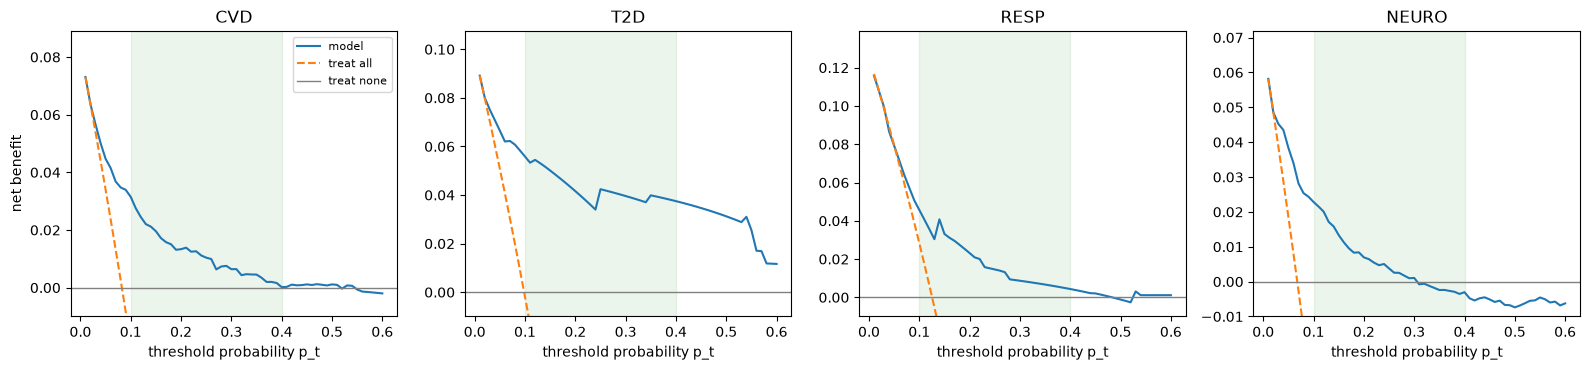

In [5]:
def plot_dca(ax, y, p, title):
    grid = np.round(np.arange(0.01, 0.61, 0.01), 2)
    nb, nb_all = E.net_benefit(y, p, grid)
    ax.plot(grid, nb, label="model")
    ax.plot(grid, nb_all, ls="--", label="treat all")
    ax.axhline(0, color="grey", lw=1, label="treat none")
    ax.axvspan(0.10, 0.40, color="green", alpha=0.08)
    ax.set_ylim(-0.01, max(nb.max(), nb_all[0]) * 1.15 + 0.005)
    ax.set_title(title); ax.set_xlabel("threshold probability p_t")

def reliability(y, p, n_bins=10):
    order = np.argsort(p, kind="stable")
    groups = np.array_split(order, n_bins)
    return np.array([p[g].mean() for g in groups]), np.array([y[g].mean() for g in groups])

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, d in zip(axes, HEADS):
    plot_dca(ax, DEV[d]["y"], DEV[d]["p"], d.upper())
axes[0].set_ylabel("net benefit"); axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_dca_calib_conf.png", dpi=200)
plt.show()

## Step 3 — Subgroup breakdown: where the gap comes from

The CV preview already flagged the subgroup gap for CVD, T2D and NEURO. Before deciding what to do,
this step finds out **why**. It uses cross-validated predictions on the 70% training partition
(about 10,500 patients), because `calib_conf` is too small to split into five subgroups reliably.
Every row is scored by a model that never saw that patient.

Two likely causes have nothing to do with unfair treatment:

- **Age restriction.** Age is one of the strongest risk factors. Over the whole cohort the model gets
  credit for ranking a 70-year-old above a 30-year-old. Inside one bracket everyone is a similar age, so
  that easy part of the ranking disappears and AUROC drops, for any model.
- **Few cases.** A bracket with few sick patients has a wide confidence interval; its AUROC can land
  far from the others by chance. Because the gap is "best minus worst", chance alone pushes it up, and
  more so in a small sample. That is why the gap on `calib_conf` (Step 2) can be larger than here.

**The test:** the domain logistic regression is scored on the same rows. If it shows about the same gap,
the gap comes from the data, not from XGBoost. Check the `case patients` column and the CI widths too.

In [6]:
SUB, gap_rows = {}, []
for d in HEADS:
    b, rec = bundles[d], records[d]
    tr = (row_part == "train").to_numpy()
    X_tr = df.loc[tr, b["feature_columns"]].astype(float)
    y_tr = df.loc[tr, "patient_id"].map(labels[f"y_{d}"]).astype(int)
    g_tr = df.loc[tr, "patient_id"]
    folds = D.make_cv_folds(y_tr, g_tr)
    scores = {
        "XGBoost": E.oof_predictions(lambda: T.make_model(rec["best_params"]), X_tr, y_tr, folds),
        "Domain LR": E.oof_predictions(E.make_lr, X_tr, y_tr, folds),
    }
    tab = E.subgroup_table(y_tr.to_numpy(), scores, g_tr.to_numpy(),
                           X_tr["biological_sex"].to_numpy(), X_tr["age"].to_numpy(), n_boot=N_BOOT)
    SUB[d] = tab.assign(head=d.upper())
    gaps = E.subgroup_gaps(tab, list(scores))
    gaps["largest gap, XGBoost"] = max(gaps["XGBoost gap (sex)"], gaps["XGBoost gap (age)"])
    gaps["largest gap, Domain LR"] = max(gaps["Domain LR gap (sex)"], gaps["Domain LR gap (age)"])
    gap_rows.append({"head": d.upper(), **gaps})
    print(f"{d.upper()} done")

gap_summary = pd.DataFrame(gap_rows).set_index("head")
gap_summary

CVD done
T2D done
RESP done
NEURO done


,XGBoost gap (sex),XGBoost gap (age),Domain LR gap (sex),Domain LR gap (age),"largest gap, XGBoost","largest gap, Domain LR"
head,,,,,,
CVD,0.015,0.040,0.011,0.025,0.040,0.025
T2D,0.005,0.030,0.002,0.026,0.030,0.026
RESP,0.012,0.040,0.012,0.035,0.040,0.035
NEURO,0.032,0.045,0.036,0.041,0.045,0.041


In [7]:
pd.concat(SUB.values()).set_index(["head", "subgroup"]).drop(columns="attribute")

rows  patients  case patients  prevalence  XGBoost AUROC XGBoost 95% CI  Domain LR AUROC Domain LR 95% CI
head  subgroup                                                                                                             
CVD   sex = 0     8436      5254            443       0.086          0.802  0.779 – 0.824            0.807    0.784 – 0.829
      sex = 1     8390      5246            444       0.089          0.817  0.796 – 0.838            0.818    0.798 – 0.840
      age 18–44   5719      3648             55       0.015          0.711  0.630 – 0.789            0.709    0.631 – 0.783
      age 45–64   5916      3731            209       0.057          0.671  0.625 – 0.712            0.692    0.648 – 0.731
      age 65–100  5191      3247            635       0.201          0.683  0.654 – 0.707            0.684    0.656 – 0.709
T2D   sex = 0     8436      5254            564       0.110          0.876  0.859 – 0.894            0.877    0.860 – 0.894
      sex = 1     8390      5246            515       0.104          0.871  0.850 – 0.891            0.875    0.854 – 0.893
      age 18–44   5719      3648            350       0.098          0.856  0.831 – 0.881            0.860    0.834 – 0.883
      age 45–64   5916      3731            360       0.099          0.876  0.851 – 0.897            0.878    0.854 – 0.900
      age 65–100  5191      3247            379       0.126          0.886  0.865 – 0.908            0.886    0.865 – 0.907
RESP  sex = 0     8436      5254            624       0.119          0.741  0.717 – 0.763            0.746    0.724 – 0.768
      sex = 1     8390      5246            674       0.129          0.729  0.706 – 0.750            0.734    0.712 – 0.755
      age 18–44   5719      3648            194       0.051          0.633  0.588 – 0.678            0.648    0.603 – 0.693
      age 45–64   5916      3731            419       0.113          0.673  0.646 – 0.700            0.683    0.656 – 0.710
      age 65–100  5191      3247            696       0.216          0.666  0.643 – 0.689            0.678    0.655 – 0.701
NEURO sex = 0     8436      5254            359       0.067          0.800  0.774 – 0.825            0.803    0.778 – 0.830
      sex = 1     8390      5246            387       0.076          0.832  0.805 – 0.855            0.839    0.811 – 0.862
      age 18–44   5719      3648             84       0.026          0.792  0.734 – 0.844            0.796    0.735 – 0.849
      age 45–64   5916      3731            209       0.056          0.782  0.743 – 0.820            0.787    0.748 – 0.826
      age 65–100  5191      3247            461       0.140          0.747  0.719 – 0.773            0.755    0.728 – 0.780

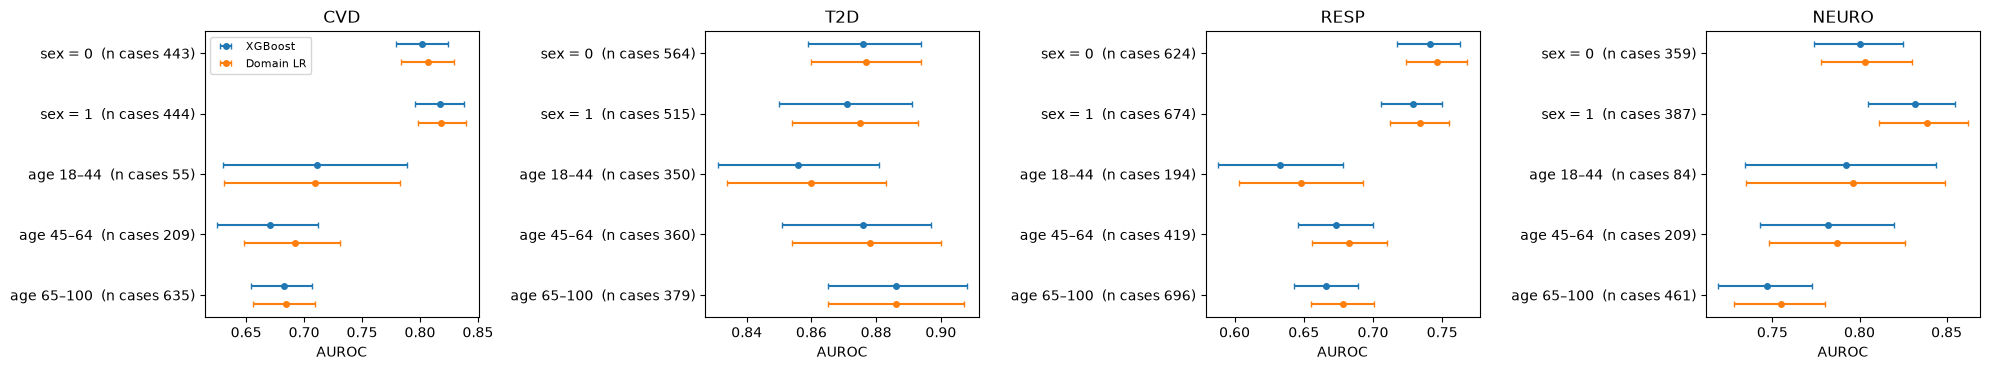

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, d in zip(axes, HEADS):
    t = SUB[d]
    ypos = np.arange(len(t))
    for off, name, color in [(-0.15, "XGBoost", "tab:blue"), (0.15, "Domain LR", "tab:orange")]:
        lo_hi = t[f"{name} 95% CI"].str.split(" – ", expand=True).astype(float)
        est = t[f"{name} AUROC"]
        ax.errorbar(est, ypos + off, xerr=[est - lo_hi[0], lo_hi[1] - est], fmt="o", ms=4,
                    color=color, label=name, capsize=2)
    ax.set_yticks(ypos, [f"{s}  (n cases {c})" for s, c in zip(t["subgroup"], t["case patients"])])
    ax.set_title(d.upper()); ax.set_xlabel("AUROC"); ax.invert_yaxis()
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_subgroup_auroc.png", dpi=200)
plt.show()

**How to read this for Chapter 4.** For each head, compare `largest gap, XGBoost` with
`largest gap, Domain LR`:

- About the same (within ~0.02), and the age brackets drive it: the gap is a property of the cohort
  (age restriction, case mix), not something XGBoost added. Re-tuning cannot fix it.
- XGBoost clearly larger: the model itself treats a group worse; this is a real remediation target.

The gate result stays as computed (§3.7.1 does not change). This step supplies the explanation that goes
with it.

## Step 4 — FHRS ablation and baselines (preview on `calib_conf`)

All comparators are trained on the same 70% training partition:

| Comparator | Inputs | Question it answers |
| --- | --- | --- |
| Domain LR | the head's full feature set | Is XGBoost non-inferior to the logistic model the generator resembles? (CI lower bound of ΔAUROC > −0.02) |
| FHRS-only LR | `adjusted_fhrs`, `fhrs_band` | How much does family history alone predict? |
| Biomarker-only LR | everything except the two FHRS inputs | How much do tests alone predict? |
| XGBoost without FHRS | same as biomarker-only, same tuned settings as the head | Ablation (§3.7.2): what the FHRS inputs add; planted drop 0.015–0.035 |

Δ = head minus comparator. For the baselines the head's calibrated ŷ is used, and NRI counts how many
patients move to a more correct risk tier. The ablation compares raw scores of both XGBoost models.

The DeLong p-value treats visits as independent; the bootstrap CI accounts for repeat visits and is the
one used for decisions. The holdout version of this table (Step 6) is the one reported in Chapter 4.

In [9]:
COMP, dev_comp = {}, []
for d in HEADS:
    tr = (row_part == "train").to_numpy()
    y_tr = df.loc[tr, "patient_id"].map(labels[f"y_{d}"]).astype(int)
    COMP[d] = E.fit_comparators(bundles[d], records[d], df.loc[tr], y_tr)
    ev = E.eval_rows(df, labels, row_part, d, "calib_conf", bundles[d]["feature_columns"])
    dev_comp.append(E.comparison_table(bundles[d], COMP[d], ev, n_boot=N_BOOT).assign(head=d.upper()))
pd.concat(dev_comp).set_index(["head", "comparison"])

comparator AUROC  head AUROC  ΔAUROC    ΔAUROC 95% CI  DeLong p  ΔAUPRC    ΔAUPRC 95% CI  tier NRI      NRI 95% CI  \
head  comparison                                                                                                                                         
CVD   XGBoost vs Domain LR                     0.774       0.771  -0.003   -0.012 – 0.007    0.4146  -0.011   -0.047 – 0.021    -0.001  -0.062 – 0.056   
      XGBoost vs FHRS-only LR                  0.613       0.771   0.158    0.083 – 0.229    0.0000   0.106    0.013 – 0.205     0.223   0.112 – 0.336   
      XGBoost vs Biomarker-only LR             0.740       0.771   0.032    0.001 – 0.065    0.0048   0.041   -0.024 – 0.102     0.114   0.021 – 0.209   
      Full XGBoost vs without FHRS             0.738       0.771   0.033    0.005 – 0.066    0.0020   0.056   -0.002 – 0.107       NaN                   
T2D   XGBoost vs Domain LR                     0.873       0.859  -0.015  -0.024 – -0.005    0.0004  -0.056  -0.087 – -0.026     0.070   0.007 – 0.139   
      XGBoost vs FHRS-only LR                  0.558       0.859   0.300    0.232 – 0.369    0.0000   0.421    0.305 – 0.518     0.582   0.472 – 0.684   
      XGBoost vs Biomarker-only LR             0.873       0.859  -0.015  -0.029 – -0.001    0.0038  -0.040  -0.073 – -0.007     0.131   0.054 – 0.213   
      Full XGBoost vs without FHRS             0.868       0.865  -0.003   -0.013 – 0.008    0.5118   0.020    0.003 – 0.037       NaN                   
RESP  XGBoost vs Domain LR                     0.714       0.711  -0.003   -0.014 – 0.009    0.5983  -0.037  -0.059 – -0.014     0.057   0.011 – 0.114   
      XGBoost vs FHRS-only LR                  0.489       0.711   0.222    0.138 – 0.302    0.0000   0.172    0.108 – 0.237     0.304   0.222 – 0.392   
      XGBoost vs Biomarker-only LR             0.716       0.711  -0.004   -0.016 – 0.006    0.3972  -0.039  -0.060 – -0.017     0.047   0.001 – 0.103   
      Full XGBoost vs without FHRS             0.716       0.715  -0.000   -0.003 – 0.002    0.6937  -0.004   -0.011 – 0.003       NaN                   
NEURO XGBoost vs Domain LR                     0.818       0.806  -0.012   -0.025 – 0.003    0.0291  -0.058  -0.110 – -0.006    -0.103  -0.220 – 0.009   
      XGBoost vs FHRS-only LR                  0.687       0.806   0.119    0.049 – 0.183    0.0000   0.015   -0.099 – 0.144     0.097  -0.053 – 0.249   
      XGBoost vs Biomarker-only LR             0.695       0.806   0.111    0.035 – 0.186    0.0000   0.045   -0.017 – 0.127     0.133   0.037 – 0.247   
      Full XGBoost vs without FHRS             0.681       0.806   0.125    0.049 – 0.203    0.0000   0.046   -0.018 – 0.129       NaN                   

                                                             verdict  
head  comparison                                                      
CVD   XGBoost vs Domain LR                              non-inferior  
      XGBoost vs FHRS-only LR                         XGBoost higher  
      XGBoost vs Biomarker-only LR                    XGBoost higher  
      Full XGBoost vs without FHRS   drop within planted 0.015–0.035  
T2D   XGBoost vs Domain LR                 non-inferiority NOT shown  
      XGBoost vs FHRS-only LR                         XGBoost higher  
      XGBoost vs Biomarker-only LR                     XGBoost lower  
      Full XGBoost vs without FHRS  drop outside planted 0.015–0.035  
RESP  XGBoost vs Domain LR                              non-inferior  
      XGBoost vs FHRS-only LR                         XGBoost higher  
      XGBoost vs Biomarker-only LR               no clear difference  
      Full XGBoost vs without FHRS  drop outside planted 0.015–0.035  
NEURO XGBoost vs Domain LR                 non-inferiority NOT shown  
      XGBoost vs FHRS-only LR                         XGBoost higher  
      XGBoost vs Biomarker-only LR                    XGBoost higher  
      Full XGBoost vs without FHRS  drop outside planted

## Step 5 — Remediation decision

**Rules (§3.7.1):** a head that fails a gate may be retrained (feature pruning, re-tuning) for at most
three cycles, judged only on Part A. A head that still fails is **quarantined**: it is still reported
on the holdout, but marked as not eligible for deployment. The holdout is never used to decide.

The first table lists what each head fails. The second is a **ceiling check** for AUROC: the domain LR
is the logistic model the generator resembles, and the reference LR also gets `bio_fhrs`, the score the
generator used to make the labels (never deployable). If even the reference stays under the target,
no amount of re-tuning will reach it, and the shortfall is a property of the cohort.

In [10]:
status = []
for d in HEADS:
    g = dev_gates[dev_gates["head"] == d.upper()]
    failed = g.loc[~g["pass"], "metric"].tolist()
    status.append({"head": d.upper(), "failed metrics": ", ".join(failed) or "none",
                   "status": "passes all gates" if not failed else "needs a decision"})
display(pd.DataFrame(status).set_index("head"))

ceiling = []
for d in HEADS:
    ev = E.eval_rows(df, labels, row_part, d, "calib_conf", bundles[d]["feature_columns"])
    sc = E.comparator_scores(COMP[d], ev["rows"])
    ceiling.append({
        "head": d.upper(),
        "target": E.AUROC_TARGET[d],
        "XGBoost head": round(roc_auc_score(ev["y"], DEV[d]["p"]), 3),
        "Domain LR": round(roc_auc_score(ev["y"], sc["Domain LR"]), 3),
        "Reference LR + BioFHRS": round(roc_auc_score(ev["y"], sc[E.REFERENCE]), 3),
    })
pd.DataFrame(ceiling).set_index("head")

,failed metrics,status
head,,
CVD,AUROC,needs a decision
T2D,"Subgroup ΔAUROC (sex, age)",needs a decision
RESP,"AUROC, Calibration slope, Subgroup ΔAUROC (sex...",needs a decision
NEURO,"Calibration slope, DCA net-benefit margin, Sub...",needs a decision


,target,XGBoost head,Domain LR,Reference LR + BioFHRS
head,,,,
CVD,0.80,0.771,0.774,0.774
T2D,0.80,0.859,0.873,0.875
RESP,0.75,0.711,0.714,0.714
NEURO,0.70,0.806,0.818,0.816


**Record the decision here before running the holdout.** One cycle = change the setting in `train.py`,
retrain that head (`uv run python experiment/src/ml/train.py --disease <d> --trials 100`), then rerun
notebook 01 and Part A of this notebook. Write what was tried and why in the log, so Chapter 4 can report it.

In [11]:
REMEDIATION_LOG = {
    "cvd":   "",
    "t2d":   "",
    "resp":  "",
    "neuro": "",
}
QUARANTINED = []       # e.g. ["resp"] if it still fails after three cycles

---
# Part B — Holdout, once

The holdout (15% of patients) has not been used anywhere so far. It is scored **once**, after Step 5.

How the guard works:

- `RUN_HOLDOUT = False` (default): nothing is computed.
- First run with `RUN_HOLDOUT = True`: every head is scored and the results are saved to
  `experiment/reports/holdout_results.json` together with the four bundle hashes.
- Any later run: the saved results are shown, not recomputed. If a bundle has changed since then
  (a model was retrained after seeing the holdout), the cell **stops with an error**, because those
  results could no longer be reported as an untouched test.

In [12]:
def run_holdout():
    out = {"evaluated_at_utc": datetime.now(timezone.utc).isoformat(), "n_boot": N_BOOT,
           "bundle_sha256": HASHES, "quarantined": QUARANTINED,
           "remediation_log": REMEDIATION_LOG, "heads": {}}
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
    for i, d in enumerate(HEADS):
        b = bundles[d]
        ev = E.eval_rows(df, labels, row_part, d, "holdout", b["feature_columns"])
        tab, info = E.evaluate_gates(b, ev, VEL, n_boot=N_BOOT)
        comp = E.comparison_table(b, COMP[d], ev, n_boot=N_BOOT)
        out["heads"][d] = {
            "gates": tab.to_dict("records"),
            "comparisons": comp.to_dict("records"),
            "conformal": E.conformal_summary(info["p"], ev["y"], b["q_hat"]),
            "sizes": {k: info[k] for k in ("n_rows", "n_patients", "n_case_patients")},
            "prevalence": info["prevalence"], "tier_change_rate": info["tier_change_rate"],
        }
        mp, fy = reliability(ev["y"], info["p"])
        ax = axes[0, i]
        lim = min(1.0, max(mp.max(), fy.max()) * 1.15)
        ax.plot(mp, fy, marker="o", ms=3); ax.plot([0, lim], [0, lim], ls="--", color="grey", lw=1)
        ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_title(f"{d.upper()} calibration (holdout)")
        ax.set_xlabel("average predicted risk")
        plot_dca(axes[1, i], ev["y"], info["p"], f"{d.upper()} decision curve (holdout)")
        print(f"{d.upper()} scored")
    axes[0, 0].set_ylabel("observed disease rate"); axes[1, 0].set_ylabel("net benefit")
    axes[1, 0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "02_holdout_calibration_dca.png", dpi=200)
    plt.close(fig)
    HOLDOUT_FILE.parent.mkdir(parents=True, exist_ok=True)
    HOLDOUT_FILE.write_text(json.dumps(out, indent=2, ensure_ascii=False,
                                       default=lambda o: o.item() if hasattr(o, "item") else str(o)))
    return out

if HOLDOUT_FILE.exists():
    H = json.loads(HOLDOUT_FILE.read_text())
    changed = [d for d in HEADS if H["bundle_sha256"].get(d) != HASHES[d]]
    if changed:
        raise RuntimeError(f"Bundles changed after the holdout was used: {changed}. These holdout results "
                           "no longer describe the saved models. Do not delete the file to rerun; report it.")
    print(f"Holdout already evaluated at {H['evaluated_at_utc']}. Showing the saved results.")
elif RUN_HOLDOUT:
    H = run_holdout()
    print(f"Holdout evaluated and saved to {HOLDOUT_FILE}")
else:
    H = None
    print("Holdout not run. Set RUN_HOLDOUT = True in the first cell once Step 5 is settled, then Run All.")

Holdout not run. Set RUN_HOLDOUT = True in the first cell once Step 5 is settled, then Run All.


### Holdout results (Chapter 4)

Gate overview, every metric with its CI, the baselines and ablation, and conformal coverage
(target about 0.90 for both sick and healthy patients).

In [13]:
if H is not None:
    hg = pd.concat([pd.DataFrame(H["heads"][d]["gates"]).assign(head=d.upper()) for d in HEADS],
                   ignore_index=True)
    summary = E.gate_summary(hg)
    summary["status"] = ["quarantined" if h.lower() in H["quarantined"] else "eligible" for h in summary.index]
    display(summary)
    display(E.fmt_gates(hg))
    display(pd.concat([pd.DataFrame(H["heads"][d]["comparisons"]).assign(head=d.upper()) for d in HEADS])
              .set_index(["head", "comparison"]))
    display(pd.DataFrame([{"head": d.upper(), **H["heads"][d]["sizes"], **H["heads"][d]["conformal"]}
                          for d in HEADS]).set_index("head"))
    fig_path = FIG_DIR / "02_holdout_calibration_dca.png"
    if fig_path.exists():
        display(Image(filename=str(fig_path)))

---
# Step 7 — Evaluation record

## What this notebook did, in order

1. **Verified the inputs.** The cohort file matched its frozen SHA-256, the patient split matched
   `partitions.csv`, and each of the four model bundles matched the fingerprint in its record. Nothing
   below can come from a different dataset or a different model.
2. **Scored the eight metrics (five gates) on `calib_conf`.** The 1,125 patients that neither training nor
   calibration used. Every metric got a 95% confidence interval from 1,000 patient-clustered bootstrap
   resamples.
3. **Diagnosed the subgroup gap** on the 70% training partition with cross-validated predictions, comparing
   XGBoost with the domain logistic regression on the same rows.
4. **Compared each head with the three logistic-regression baselines and its FHRS ablation**, and checked
   the AUROC ceiling with a reference model that also sees `bio_fhrs`.
5. **Recorded the remediation decision** for each failing head (Step 5), before any holdout result existed.
6. **Scored the holdout once** (Part B), only after Step 5, with the results frozen to the bundle hashes.

## How this follows Chapter 3

| Chapter 3 requirement | Where | How it is computed |
| --- | --- | --- |
| §3.7.1 AUROC ≥ 0.80 / 0.80 / 0.75 / 0.70 | Step 2, gate 1 | `roc_auc_score` on calibrated ŷ |
| §3.7.1 AUPRC ≥ 2 × prevalence of the evaluation partition | Step 2, gate 1 | average precision; π = disease rate of the rows scored |
| §3.7.1 ECE ≤ 0.05, 10 equal-frequency bins | Step 2, gate 2 | `train.ece` (deciles) |
| §3.7.1 Brier < π(1 − π) | Step 2, gate 2 | `brier_score_loss` |
| §3.7.1 calibration slope 0.90–1.10 | Step 2, gate 2 | logistic recalibration of y on logit(ŷ) |
| §3.7.1 DCA better than treat-all / treat-none, p_t 0.10–0.40 | Step 2, gate 3 | smallest margin over p_t = 0.10, 0.11 … 0.40; pass if never below 0 |
| §3.7.1 subgroup ΔAUROC < 0.05, sex and ages 18–44 / 45–64 / 65–100 | Step 2, gate 4; Step 3 | best minus worst AUROC, within sex and within age |
| §3.7.1 ICC(2,1) ≥ 0.85 under ±2% noise | Step 2, gate 5 | 10 noisy copies of every lab value, velocity recomputed |
| §3.7.1 95% CI, patient-clustered bootstrap | every metric | patients resampled with all their visits |
| §3.7.1 gates first on CV and calibration-partition predictions | notebook 01 (CV), Step 2 (`calib_conf`) | |
| §3.7.1 remediation ≤ 3 cycles, else quarantine | Step 5 | `REMEDIATION_LOG`, `QUARANTINED` |
| §3.7.1 holdout once, never used for tuning | Part B | saved with bundle hashes; rerun refuses changed models |
| §3.7.2 FHRS ablation: ΔAUROC (DeLong), ΔAUPRC (bootstrap CI) | Step 4 | same tuned settings, FHRS inputs removed |
| §3.7.3 three LR baselines, ΔAUROC (DeLong), tier NRI, 95% CIs | Step 4 | |
| §3.7.3 non-inferiority: lower 95% CI bound of ΔAUROC > −0.02 | Step 4 | bootstrap CI vs domain LR |

**Choices the chapter leaves open, stated here:**
- A gate passes when its point estimate meets the target; the CI is reported beside it.
- DCA "superior" is read as "never below treat-all or treat-none": at high thresholds where the model flags
  no one, it ties treat-none, which is not counted as a loss.
- DeLong treats visits as independent, so decisions use the patient-clustered bootstrap CI and the DeLong
  p-value is reported beside it.
- The ablation reuses the head's tuned settings instead of re-tuning.
- Step 3 (subgroup diagnosis) and the ceiling check in Step 5 are diagnostics, not gates.

The cell below writes the results. It reads the numbers from this run, so after a rerun the text always
matches the tables above. It is also saved to `experiment/reports/02_evaluation_summary.md`.

In [14]:
from IPython.display import Markdown

def md_table(frame):
    f = frame.reset_index()
    cols = [str(c) for c in f.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + " --- |" * len(cols)]
    for row in f.itertuples(index=False):
        out.append("| " + " | ".join("" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)
                                     for v in row) + " |")
    return "\n".join(out)

def ci_text(row):
    k = 4 if row["metric"] == "Brier" else 3
    return f"{row['estimate']:.{k}f} (95% CI {row['ci_low']:.{k}f} to {row['ci_high']:.{k}f})"

L = ["# Evaluation record (notebook 02)", "",
     f"Generated {datetime.now(timezone.utc):%Y-%m-%d %H:%M} UTC · cohort `{D.COHORT_SHA256[:12]}…` · "
     f"{N_BOOT} bootstrap resamples · bundles " +
     ", ".join(f"{d.upper()} `{HASHES[d][:12]}…`" for d in HEADS), ""]

sizes = pd.DataFrame({"patients": part.value_counts(), "visits": row_part.value_counts()}).rename_axis("partition")
L += ["## 1. Data", "", md_table(sizes.loc[["train", "calib_iso", "calib_conf", "holdout"]]), ""]

L += ["## 2. Gates on calib_conf", "", md_table(E.gate_summary(dev_gates)), ""]
for d in HEADS:
    g = dev_gates[dev_gates["head"] == d.upper()]
    fails = g[~g["pass"]]
    info = DEV[d]
    line = (f"- **{d.upper()}** ({info['n_patients']:,} patients, {info['n_case_patients']} with the disease): ")
    if fails.empty:
        line += "passes all eight metrics."
    else:
        line += "fails " + "; ".join(f"{r['metric']} {ci_text(r)}, target {r['target']}" for _, r in fails.iterrows()) + "."
    L.append(line)
L += ["", "Every metric:", "", md_table(E.fmt_gates(dev_gates)), ""]

L += ["## 3. Subgroup diagnosis (training partition, cross-validated)", "", md_table(gap_summary), ""]
for d in HEADS:
    r = gap_summary.loc[d.upper()]
    x, l = r["largest gap, XGBoost"], r["largest gap, Domain LR"]
    L.append(f"- **{d.upper()}**: largest gap {x:.3f} (XGBoost) vs {l:.3f} (domain LR); "
             f"{'below' if x < E.SUBGROUP_MAX_GAP else 'above'} the {E.SUBGROUP_MAX_GAP} target on this larger sample; "
             f"{'about the same as logistic regression, so it comes from the data' if x - l <= 0.02 else 'larger than logistic regression, so it is model-specific'}.")
L.append("")

comp = pd.concat(dev_comp).set_index(["head", "comparison"])
keep = ["comparator AUROC", "head AUROC", "ΔAUROC", "ΔAUROC 95% CI", "DeLong p", "tier NRI", "NRI 95% CI", "verdict"]
L += ["## 4. Baselines and FHRS ablation (calib_conf)", "", md_table(comp[keep]), ""]

L += ["## 5. AUROC ceiling check (calib_conf)", "", md_table(pd.DataFrame(ceiling).set_index("head")), ""]
for r in ceiling:
    best = max(r["Domain LR"], r["Reference LR + BioFHRS"])
    if r["XGBoost head"] < r["target"]:
        L.append(f"- **{r['head']}** is below its target ({r['XGBoost head']:.3f} < {r['target']:.2f}); "
                 + ("even the reference model stays below it, so the shortfall is a property of the cohort."
                    if best < r["target"] else "the reference model reaches it, so re-tuning may help."))
L.append("")

rem = []
for d in HEADS:
    g = dev_gates[dev_gates["head"] == d.upper()]
    failed = g.loc[~g["pass"], "metric"].tolist()
    rem.append({"head": d.upper(), "failed metrics": ", ".join(failed) or "none",
                "decision / cycles tried": REMEDIATION_LOG.get(d) or "(not recorded yet)",
                "status": "quarantined" if d in QUARANTINED else ("eligible" if not failed else "eligible, failures reported")})
L += ["## 6. Remediation", "", md_table(pd.DataFrame(rem).set_index("head")), ""]

L += ["## 7. Holdout", ""]
if H is None:
    L.append("Not run yet. The holdout stays untouched until `RUN_HOLDOUT = True`.")
else:
    hg = pd.concat([pd.DataFrame(H["heads"][d]["gates"]).assign(head=d.upper()) for d in HEADS], ignore_index=True)
    hs = E.gate_summary(hg)
    hs["status"] = ["quarantined" if h.lower() in H["quarantined"] else "eligible" for h in hs.index]
    hc = pd.concat([pd.DataFrame(H["heads"][d]["comparisons"]).assign(head=d.upper()) for d in HEADS]).set_index(["head", "comparison"])
    conf = pd.DataFrame([{"head": d.upper(), **H["heads"][d]["sizes"], **H["heads"][d]["conformal"]} for d in HEADS]).set_index("head")
    L += [f"Evaluated once at {H['evaluated_at_utc']}.", "", md_table(hs), "", md_table(E.fmt_gates(hg)), "",
          md_table(hc[keep]), "", "Conformal coverage (target ≈ 0.90 for each class):", "", md_table(conf)]

L += ["", "Figures: `experiment/reports/figures/` — " +
      ", ".join(f"`{p.name}`" for p in sorted(FIG_DIR.glob("02_*.png")))]

report = "\n".join(L)
(ROOT / "experiment" / "reports" / "02_evaluation_summary.md").write_text(report, encoding="utf-8")
display(Markdown(report))

# Evaluation record (notebook 02)

Generated 2026-10-13 22:04 UTC · cohort `23d28b00c57b…` · 1000 bootstrap resamples · bundles CVD `84e20c012900…`, T2D `529335855f75…`, RESP `a5c5b67b2609…`, NEURO `2db52e4522bc…`

## 1. Data

| partition | patients | visits |
| --- | --- | --- |
| train | 10500 | 16826 |
| calib_iso | 1125 | 1843 |
| calib_conf | 1125 | 1761 |
| holdout | 2250 | 3566 |

## 2. Gates on calib_conf

| head | 1 Discrimination | 2 Calibration | 3 Clinical utility | 4 Subgroup fairness | 5 Stability | all gates |
| --- | --- | --- | --- | --- | --- | --- |
| CVD | FAIL | pass | pass | pass | pass | FAIL |
| T2D | pass | pass | pass | FAIL | pass | FAIL |
| RESP | FAIL | FAIL | pass | FAIL | pass | FAIL |
| NEURO | pass | FAIL | FAIL | FAIL | pass | FAIL |

- **CVD** (1,125 patients, 97 with the disease): fails AUROC 0.771 (95% CI 0.711 to 0.825), target ≥ 0.80.
- **T2D** (1,125 patients, 115 with the disease): fails Subgroup ΔAUROC (sex, age) 0.071 (95% CI 0.042 to 0.211), target < 0.05.
- **RESP** (1,125 patients, 140 with the disease): fails AUROC 0.711 (95% CI 0.658 to 0.760), target ≥ 0.75; Calibration slope 0.698 (95% CI 0.380 to 1.080), target 0.90–1.10; Subgroup ΔAUROC (sex, age) 0.071 (95% CI 0.037 to 0.201), target < 0.05.
- **NEURO** (1,125 patients, 79 with the disease): fails Calibration slope 0.840 (95% CI 0.672 to 1.040), target 0.90–1.10; DCA net-benefit margin -0.004 (95% CI -0.012 to 0.005), target ≥ 0 for every p_t in 0.10–0.40; Subgroup ΔAUROC (sex, age) 0.064 (95% CI 0.029 to 0.236), target < 0.05.

Every metric:

| head | gate | metric | estimate | 95% CI | target | pass |
| --- | --- | --- | --- | --- | --- | --- |
| CVD | 1 Discrimination | AUROC | 0.771 | 0.711 – 0.825 | ≥ 0.80 | FAIL |
| CVD | 1 Discrimination | AUPRC | 0.287 | 0.203 – 0.394 | ≥ 2π = 0.165 | pass |
| CVD | 2 Calibration | ECE | 0.014 | 0.013 – 0.036 | ≤ 0.05 | pass |
| CVD | 2 Calibration | Brier | 0.0676 | 0.0554 – 0.0814 | < π(1−π) = 0.0756 | pass |
| CVD | 2 Calibration | Calibration slope | 0.970 | 0.761 – 1.196 | 0.90–1.10 | pass |
| CVD | 3 Clinical utility | DCA net-benefit margin | 0.000 | -0.006 – 0.006 | ≥ 0 for every p_t in 0.10–0.40 | pass |
| CVD | 4 Subgroup fairness | Subgroup ΔAUROC (sex, age) | 0.040 | 0.037 – 0.281 | < 0.05 | pass |
| CVD | 5 Stability | ICC(2,1) under ±2% lab noise | 0.996 | 0.994 – 0.997 | ≥ 0.85 | pass |
| T2D | 1 Discrimination | AUROC | 0.859 | 0.800 – 0.909 | ≥ 0.80 | pass |
| T2D | 1 Discrimination | AUPRC | 0.562 | 0.450 – 0.662 | ≥ 2π = 0.196 | pass |
| T2D | 2 Calibration | ECE | 0.020 | 0.016 – 0.041 | ≤ 0.05 | pass |
| T2D | 2 Calibration | Brier | 0.0585 | 0.0469 – 0.0709 | < π(1−π) = 0.0886 | pass |
| T2D | 2 Calibration | Calibration slope | 0.905 | 0.605 – 1.220 | 0.90–1.10 | pass |
| T2D | 3 Clinical utility | DCA net-benefit margin | 0.034 | 0.016 – 0.050 | ≥ 0 for every p_t in 0.10–0.40 | pass |
| T2D | 4 Subgroup fairness | Subgroup ΔAUROC (sex, age) | 0.071 | 0.042 – 0.211 | < 0.05 | FAIL |
| T2D | 5 Stability | ICC(2,1) under ±2% lab noise | 0.981 | 0.973 – 0.986 | ≥ 0.85 | pass |
| RESP | 1 Discrimination | AUROC | 0.711 | 0.658 – 0.760 | ≥ 0.75 | FAIL |
| RESP | 1 Discrimination | AUPRC | 0.298 | 0.235 – 0.375 | ≥ 2π = 0.251 | pass |
| RESP | 2 Calibration | ECE | 0.026 | 0.021 – 0.049 | ≤ 0.05 | pass |
| RESP | 2 Calibration | Brier | 0.1007 | 0.0864 – 0.1164 | < π(1−π) = 0.1097 | pass |
| RESP | 2 Calibration | Calibration slope | 0.698 | 0.380 – 1.080 | 0.90–1.10 | FAIL |
| RESP | 3 Clinical utility | DCA net-benefit margin | 0.004 | -0.004 – 0.013 | ≥ 0 for every p_t in 0.10–0.40 | pass |
| RESP | 4 Subgroup fairness | Subgroup ΔAUROC (sex, age) | 0.071 | 0.037 – 0.201 | < 0.05 | FAIL |
| RESP | 5 Stability | ICC(2,1) under ±2% lab noise | 0.956 | 0.946 – 0.965 | ≥ 0.85 | pass |
| NEURO | 1 Discrimination | AUROC | 0.806 | 0.753 – 0.854 | ≥ 0.70 | pass |
| NEURO | 1 Discrimination | AUPRC | 0.259 | 0.181 – 0.366 | ≥ 2π = 0.135 | pass |
| NEURO | 2 Calibration | ECE | 0.022 | 0.014 – 0.043 | ≤ 0.05 | pass |
| NEURO | 2 Calibration | Brier | 0.0588 | 0.0467 – 0.0719 | < π(1−π) = 0.0630 | pass |
| NEURO | 2 Calibration | Calibration slope | 0.840 | 0.672 – 1.040 | 0.90–1.10 | FAIL |
| NEURO | 3 Clinical utility | DCA net-benefit margin | -0.004 | -0.012 – 0.005 | ≥ 0 for every p_t in 0.10–0.40 | FAIL |
| NEURO | 4 Subgroup fairness | Subgroup ΔAUROC (sex, age) | 0.064 | 0.029 – 0.236 | < 0.05 | FAIL |
| NEURO | 5 Stability | ICC(2,1) under ±2% lab noise | 0.994 | 0.992 – 0.996 | ≥ 0.85 | pass |

## 3. Subgroup diagnosis (training partition, cross-validated)

| head | XGBoost gap (sex) | XGBoost gap (age) | Domain LR gap (sex) | Domain LR gap (age) | largest gap, XGBoost | largest gap, Domain LR |
| --- | --- | --- | --- | --- | --- | --- |
| CVD | 0.015 | 0.04 | 0.011 | 0.025 | 0.04 | 0.025 |
| T2D | 0.005 | 0.03 | 0.002 | 0.026 | 0.03 | 0.026 |
| RESP | 0.012 | 0.04 | 0.012 | 0.035 | 0.04 | 0.035 |
| NEURO | 0.032 | 0.045 | 0.036 | 0.041 | 0.045 | 0.041 |

- **CVD**: largest gap 0.040 (XGBoost) vs 0.025 (domain LR); below the 0.05 target on this larger sample; about the same as logistic regression, so it comes from the data.
- **T2D**: largest gap 0.030 (XGBoost) vs 0.026 (domain LR); below the 0.05 target on this larger sample; about the same as logistic regression, so it comes from the data.
- **RESP**: largest gap 0.040 (XGBoost) vs 0.035 (domain LR); below the 0.05 target on this larger sample; about the same as logistic regression, so it comes from the data.
- **NEURO**: largest gap 0.045 (XGBoost) vs 0.041 (domain LR); below the 0.05 target on this larger sample; about the same as logistic regression, so it comes from the data.

## 4. Baselines and FHRS ablation (calib_conf)

| head | comparison | comparator AUROC | head AUROC | ΔAUROC | ΔAUROC 95% CI | DeLong p | tier NRI | NRI 95% CI | verdict |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CVD | XGBoost vs Domain LR | 0.774 | 0.771 | -0.003 | -0.012 – 0.007 | 0.4146 | -0.001 | -0.062 – 0.056 | non-inferior |
| CVD | XGBoost vs FHRS-only LR | 0.613 | 0.771 | 0.158 | 0.083 – 0.229 | 0.0 | 0.223 | 0.112 – 0.336 | XGBoost higher |
| CVD | XGBoost vs Biomarker-only LR | 0.74 | 0.771 | 0.032 | 0.001 – 0.065 | 0.0048 | 0.114 | 0.021 – 0.209 | XGBoost higher |
| CVD | Full XGBoost vs without FHRS | 0.738 | 0.771 | 0.033 | 0.005 – 0.066 | 0.002 |  |  | drop within planted 0.015–0.035 |
| T2D | XGBoost vs Domain LR | 0.873 | 0.859 | -0.015 | -0.024 – -0.005 | 0.0004 | 0.07 | 0.007 – 0.139 | non-inferiority NOT shown |
| T2D | XGBoost vs FHRS-only LR | 0.558 | 0.859 | 0.3 | 0.232 – 0.369 | 0.0 | 0.582 | 0.472 – 0.684 | XGBoost higher |
| T2D | XGBoost vs Biomarker-only LR | 0.873 | 0.859 | -0.015 | -0.029 – -0.001 | 0.0038 | 0.131 | 0.054 – 0.213 | XGBoost lower |
| T2D | Full XGBoost vs without FHRS | 0.868 | 0.865 | -0.003 | -0.013 – 0.008 | 0.5118 |  |  | drop outside planted 0.015–0.035 |
| RESP | XGBoost vs Domain LR | 0.714 | 0.711 | -0.003 | -0.014 – 0.009 | 0.5983 | 0.057 | 0.011 – 0.114 | non-inferior |
| RESP | XGBoost vs FHRS-only LR | 0.489 | 0.711 | 0.222 | 0.138 – 0.302 | 0.0 | 0.304 | 0.222 – 0.392 | XGBoost higher |
| RESP | XGBoost vs Biomarker-only LR | 0.716 | 0.711 | -0.004 | -0.016 – 0.006 | 0.3972 | 0.047 | 0.001 – 0.103 | no clear difference |
| RESP | Full XGBoost vs without FHRS | 0.716 | 0.715 | -0.0 | -0.003 – 0.002 | 0.6937 |  |  | drop outside planted 0.015–0.035 |
| NEURO | XGBoost vs Domain LR | 0.818 | 0.806 | -0.012 | -0.025 – 0.003 | 0.0291 | -0.103 | -0.220 – 0.009 | non-inferiority NOT shown |
| NEURO | XGBoost vs FHRS-only LR | 0.687 | 0.806 | 0.119 | 0.049 – 0.183 | 0.0 | 0.097 | -0.053 – 0.249 | XGBoost higher |
| NEURO | XGBoost vs Biomarker-only LR | 0.695 | 0.806 | 0.111 | 0.035 – 0.186 | 0.0 | 0.133 | 0.037 – 0.247 | XGBoost higher |
| NEURO | Full XGBoost vs without FHRS | 0.681 | 0.806 | 0.125 | 0.049 – 0.203 | 0.0 |  |  | drop outside planted 0.015–0.035 |

## 5. AUROC ceiling check (calib_conf)

| head | target | XGBoost head | Domain LR | Reference LR + BioFHRS |
| --- | --- | --- | --- | --- |
| CVD | 0.8 | 0.771 | 0.774 | 0.774 |
| T2D | 0.8 | 0.859 | 0.873 | 0.875 |
| RESP | 0.75 | 0.711 | 0.714 | 0.714 |
| NEURO | 0.7 | 0.806 | 0.818 | 0.816 |

- **CVD** is below its target (0.771 < 0.80); even the reference model stays below it, so the shortfall is a property of the cohort.
- **RESP** is below its target (0.711 < 0.75); even the reference model stays below it, so the shortfall is a property of the cohort.

## 6. Remediation

| head | failed metrics | decision / cycles tried | status |
| --- | --- | --- | --- |
| CVD | AUROC | (not recorded yet) | eligible, failures reported |
| T2D | Subgroup ΔAUROC (sex, age) | (not recorded yet) | eligible, failures reported |
| RESP | AUROC, Calibration slope, Subgroup ΔAUROC (sex, age) | (not recorded yet) | eligible, failures reported |
| NEURO | Calibration slope, DCA net-benefit margin, Subgroup ΔAUROC (sex, age) | (not recorded yet) | eligible, failures reported |

## 7. Holdout

Not run yet. The holdout stays untouched until `RUN_HOLDOUT = True`.

Figures: `experiment/reports/figures/` — `02_dca_calib_conf.png`, `02_subgroup_auroc.png`